# Section 3a — Early Detection of Emerging Discussions
### The application: CELF sensor placement

Sections 1-2 asked *"who should we seed to spread a message furthest?"*
This notebook **inverts the objective**: *"who should we WATCH to learn about things earliest?"*

Same algorithm, same submodularity, same non-redundancy logic. Only the reward changes.

| | Sections 1-2 | Section 3 |
|---|---|---|
| The k users are | broadcasters | **sensors** |
| Maximise | people reached | **outbreaks detected, early** |
| Redundancy problem | seeds reaching the same audience | **sensors watching the same threads** |

**Why this needed our own scraped data:** detection time requires real timestamps on real
discussions. NetHEPT, Epinions and DBLP are static snapshots with no cascade timing. This study
is impossible on a benchmark dataset - which is the answer to "why not just use a dataset?"

**Requires** `data/hn_interactions_v3_CLEAN.csv` (the 127 MB file with timestamps).

In [1]:
import csv, random, time, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
from datetime import datetime
from pathlib import Path
Path("figures").mkdir(exist_ok=True); Path("data").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi":120,"savefig.dpi":300,"font.size":11})
SEED=42; random.seed(SEED); np.random.seed(SEED)
print("setup complete")

setup complete


## 3.1 — Build the detection benchmark (APP-1)

- **Outbreak** = a discussion with >=10 distinct participants (something worth knowing about)
- **Detection time** = hours from a discussion's first comment until one of our sensors participates
- **Non-outbreaks** = smaller discussions, needed later to measure false alarms

In [2]:
t0=time.time()
story=defaultdict(list); parts=defaultdict(set)
with open("data/hn_interactions_v3_CLEAN.csv", encoding="utf-8") as f:
    for r in csv.DictReader(f):
        ts=datetime.fromisoformat(r["timestamp_utc"]).timestamp()
        story[r["story_id"]].append((ts, r["replier_username"]))
        parts[r["story_id"]].add(r["replier_username"])
print(f"parsed {len(story):,} discussions in {time.time()-t0:.1f}s")

MIN_PARTICIPANTS=10
OUTBREAKS={s:sorted(v) for s,v in story.items() if len(parts[s])>=MIN_PARTICIPANTS}
NON_OUTBREAKS=[s for s in story if len(parts[s])<MIN_PARTICIPANTS]
OB=list(OUTBREAKS)
print(f"outbreaks (>={MIN_PARTICIPANTS} participants): {len(OUTBREAKS):,}")
print(f"non-outbreaks: {len(NON_OUTBREAKS):,}")

# first-arrival time of each user in each outbreak, plus time-to-half-activity
arrival=defaultdict(dict); half_time={}
for s,ev in OUTBREAKS.items():
    t_start=ev[0][0]
    for ts,u in ev:
        h=(ts-t_start)/3600
        if s not in arrival[u] or h<arrival[u][s]: arrival[u][s]=h
    half_time[s]=(ev[len(ev)//2][0]-t_start)/3600

arrival_non=defaultdict(set)
for s in NON_OUTBREAKS:
    for _,u in story[s]: arrival_non[u].add(s)

HORIZON=float(np.percentile([max(a.values()) for a in arrival.values() if a],95))
life=[ (v[-1][0]-v[0][0])/3600 for v in OUTBREAKS.values() ]
print(f"\ncandidate sensors (users): {len(arrival):,}")
print(f"median discussion lifespan   : {np.median(life):.1f}h")
print(f"median time-to-half-activity : {np.median(list(half_time.values())):.1f}h")
print(f"detection horizon (p95)      : {HORIZON:.1f}h")

parsed 13,772 discussions in 1.8s
outbreaks (>=10 participants): 3,418
non-outbreaks: 10,354

candidate sensors (users): 6,411
median discussion lifespan   : 56.4h
median time-to-half-activity : 5.4h
detection horizon (p95)      : 138.7h


## 3.2 — Detection objective + CELF (APP-2)

**Reward(S)** = for every outbreak, how much earlier than the horizon our sensors caught it,
summed and normalised. Undetected outbreaks contribute zero.

This function is **monotone and submodular** - adding a sensor never reduces reward, and its
marginal value shrinks as other sensors are added. So the (1-1/e) approximation guarantee from
the survey still applies, and CELF's lazy evaluation remains valid. **State this in your methodology.**

In [4]:
def reward(S):
    # Submodular detection reward: earlier detection = higher reward
    tot=0.0
    for s in OB:
        best=None
        for u in S:
            t=arrival[u].get(s)
            if t is not None and (best is None or t<best): best=t
        if best is not None: tot+=HORIZON-best
    return tot/(len(OB)*HORIZON)

def performance(S):
    # Detection rate, mean delay, false alarms, precision
    det=0; times=[]
    for s in OB:
        ts=[arrival[u][s] for u in S if s in arrival[u]]
        if ts: det+=1; times.append(min(ts))
    fa=len(set().union(*[arrival_non[u] for u in S])) if S else 0
    tp=det
    prec=tp/(tp+fa) if (tp+fa) else 0.0
    return {"detection_rate":det/len(OB),
            "mean_delay_h":float(np.mean(times)) if times else np.nan,
            "median_delay_h":float(np.median(times)) if times else np.nan,
            "false_alarms":fa, "precision":prec}

CANDIDATES=sorted(arrival, key=lambda u:-len(arrival[u]))[:500]
print(f"candidate pool: {len(CANDIDATES)} most-active users")

def celf_detect(k, verbose=False):
    t0=time.time(); evals=0
    Q=[(c,reward([c])) for c in CANDIDATES]; evals+=len(CANDIDATES)
    Q.sort(key=lambda x:-x[1])
    S=[Q[0][0]]; cur=Q[0][1]; Q=Q[1:]
    while len(S)<k:
        ok=False
        while not ok:
            cand=Q[0][0]; g=reward(S+[cand])-cur; evals+=1
            Q[0]=(cand,g); Q.sort(key=lambda x:-x[1]); ok=(Q[0][0]==cand)
        cur+=Q[0][1]; S.append(Q[0][0]); Q=Q[1:]
        if verbose: print(f"  sensor {len(S)}: reward={cur:.4f}")
    return S, cur, evals, time.time()-t0

S_test,r_test,e_test,t_test=celf_detect(10)
print(f"\nCELF k=10: reward={r_test:.4f} | {e_test:,} evaluations | {t_test:.1f}s")
print("detection:", {k:(round(v,3) if isinstance(v,float) else v) for k,v in performance(S_test).items()})

candidate pool: 500 most-active users

CELF k=10: reward=0.3648 | 1,118 evaluations | 1.0s
detection: {'detection_rate': 0.386, 'mean_delay_h': 7.479, 'median_delay_h': 3.566, 'false_alarms': 202, 'precision': 0.867}


## 3.3 — Compare against baselines

- **top-reach** - users active in the most discussions (the obvious greedy choice)
- **degree / PageRank** - the structural heuristics from Section 2
- **random** - averaged over 10 draws

In [5]:
K_VALUES=[1,5,10,15,20,25,30]
byreach=sorted(arrival,key=lambda u:-len(arrival[u]))

struct={}
try:
    m=pd.read_csv("data/gephi_node_metrics.csv")
    idc="Id" if "Id" in m.columns else m.columns[0]
    lab=pd.read_csv("data/gephi_nodes.csv")
    hash2user=None   # metrics are keyed by hash; arrivals by username
    print("(structural baselines use hashed ids - skipped unless a mapping exists)")
except FileNotFoundError:
    print("(no metrics file - structural baselines skipped)")

rows=[]
for k in K_VALUES:
    S,rw,ev,tt=celf_detect(k)
    p=performance(S); p.update({"algorithm":"CELF-detect","k":k,"runtime_s":tt,"evaluations":ev})
    rows.append(p)

    p=performance(byreach[:k]); p.update({"algorithm":"Top-reach","k":k})
    rows.append(p)

    accum=defaultdict(list)
    for i in range(10):
        random.seed(SEED+i)
        p=performance(random.sample(list(arrival),k))
        for kk,vv in p.items(): accum[kk].append(vv)
    p={kk:float(np.nanmean(vv)) for kk,vv in accum.items()}
    p.update({"algorithm":"Random","k":k}); rows.append(p)
    print(f"k={k:>2} done")

det=pd.DataFrame(rows)
det.to_csv("data/detection_results.csv", index=False)
display(det.pivot_table(index="k",columns="algorithm",values="detection_rate").round(3))

(structural baselines use hashed ids - skipped unless a mapping exists)
k= 1 done
k= 5 done
k=10 done
k=15 done
k=20 done
k=25 done
k=30 done


algorithm,CELF-detect,Random,Top-reach
k,,,
1,0.089,0.009,0.089
5,0.270,0.042,0.268
10,0.386,0.083,0.362
15,0.461,0.111,0.422
20,0.521,0.141,0.464
25,0.571,0.163,0.503
30,0.612,0.185,0.541


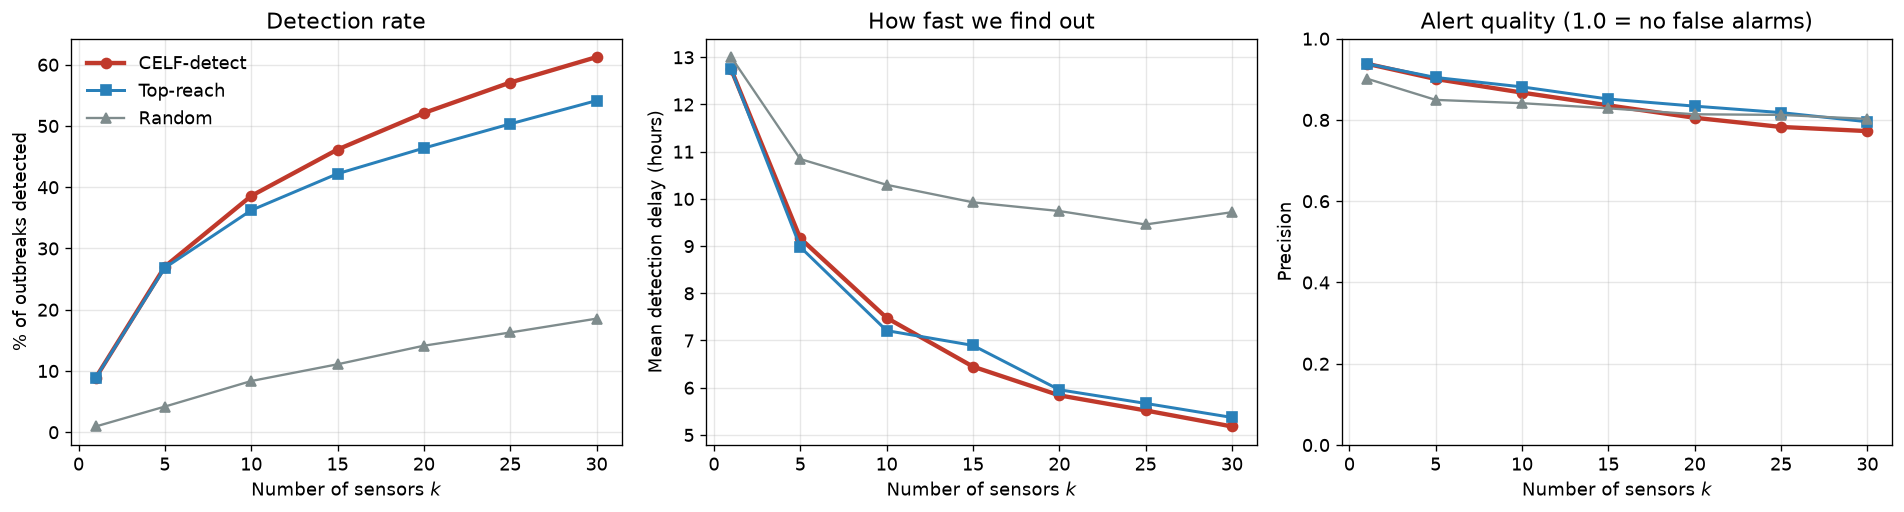

In [6]:
fig,ax=plt.subplots(1,3,figsize=(16,4.4))
style={"CELF-detect":("#c0392b","o",2.6),"Top-reach":("#2980b9","s",1.8),"Random":("#7f8c8d","^",1.4)}
for alg,(col,mk,lw) in style.items():
    d=det[det.algorithm==alg].sort_values("k")
    ax[0].plot(d.k,100*d.detection_rate,label=alg,color=col,marker=mk,lw=lw)
    ax[1].plot(d.k,d.mean_delay_h,label=alg,color=col,marker=mk,lw=lw)
    ax[2].plot(d.k,d.precision,label=alg,color=col,marker=mk,lw=lw)
ax[0].set_xlabel("Number of sensors $k$"); ax[0].set_ylabel("% of outbreaks detected")
ax[0].set_title("Detection rate"); ax[0].legend(frameon=False); ax[0].grid(alpha=.3)
ax[1].set_xlabel("Number of sensors $k$"); ax[1].set_ylabel("Mean detection delay (hours)")
ax[1].set_title("How fast we find out"); ax[1].grid(alpha=.3)
ax[2].set_xlabel("Number of sensors $k$"); ax[2].set_ylabel("Precision")
ax[2].set_title("Alert quality (1.0 = no false alarms)"); ax[2].grid(alpha=.3); ax[2].set_ylim(0,1)
plt.tight_layout(); plt.savefig("figures/fig_detection_vs_k.png",bbox_inches="tight"); plt.show()

## 3.4 — Precision, false alarms and lead time (APP-6, APP-7)

**Recall alone is misleading.** 52% detection sounds good, but if the sensors also fire on
hundreds of trivial threads the team drowns in noise. Precision answers that.

**Lead time** answers the operational question: how much warning before the discussion peaks?

In [7]:
K_REPORT=20
S_final,_,_,_=celf_detect(K_REPORT)
p=performance(S_final)

print(f"=== OPERATIONAL SUMMARY: {K_REPORT} SENSORS ===")
print(f"  outbreaks detected   : {100*p['detection_rate']:.1f}%  ({int(p['detection_rate']*len(OB)):,} of {len(OB):,})")
print(f"  mean detection delay : {p['mean_delay_h']:.2f}h")
print(f"  median delay         : {p['median_delay_h']:.2f}h")
print(f"  false alarms         : {p['false_alarms']:,} minor threads")
print(f"  precision            : {p['precision']:.2f}  ({100*p['precision']:.0f}% of alerts are real)")

# lead time: detection vs time-to-half-activity
leads=[]
for s in OB:
    ts=[arrival[u][s] for u in S_final if s in arrival[u]]
    if ts: leads.append(half_time[s]-min(ts))
leads=np.array(leads)
print(f"\n=== LEAD TIME (APP-7) ===")
print(f"  median lead before half-activity : {np.median(leads):+.2f}h")
print(f"  % detected BEFORE half-activity  : {100*(leads>0).mean():.1f}%")

days=(max(max(v[-1][0] for v in OUTBREAKS.values()),0)-min(v[0][0] for v in OUTBREAKS.values()))/86400
print(f"\n  alerts per day (approx) : {(p['detection_rate']*len(OB)+p['false_alarms'])/days:.1f}")
print(f"  -> a manageable workload for one analyst" )

json.dump({"k":K_REPORT,"sensors":S_final,**{kk:(float(vv) if isinstance(vv,(int,float,np.floating)) else vv) for kk,vv in p.items()},
           "median_lead_h":float(np.median(leads)),"pct_before_half":float(100*(leads>0).mean())},
          open("data/detection_summary.json","w"), indent=2)
pd.DataFrame({"sensor":S_final,"rank":range(1,len(S_final)+1)}).to_csv("data/sensors.csv",index=False)
print("\nsaved data/detection_summary.json and data/sensors.csv")

=== OPERATIONAL SUMMARY: 20 SENSORS ===
  outbreaks detected   : 52.1%  (1,781 of 3,418)
  mean detection delay : 5.84h
  median delay         : 2.63h
  false alarms         : 431 minor threads
  precision            : 0.81  (81% of alerts are real)

=== LEAD TIME (APP-7) ===
  median lead before half-activity : +2.45h
  % detected BEFORE half-activity  : 77.6%

  alerts per day (approx) : 6.1
  -> a manageable workload for one analyst

saved data/detection_summary.json and data/sensors.csv


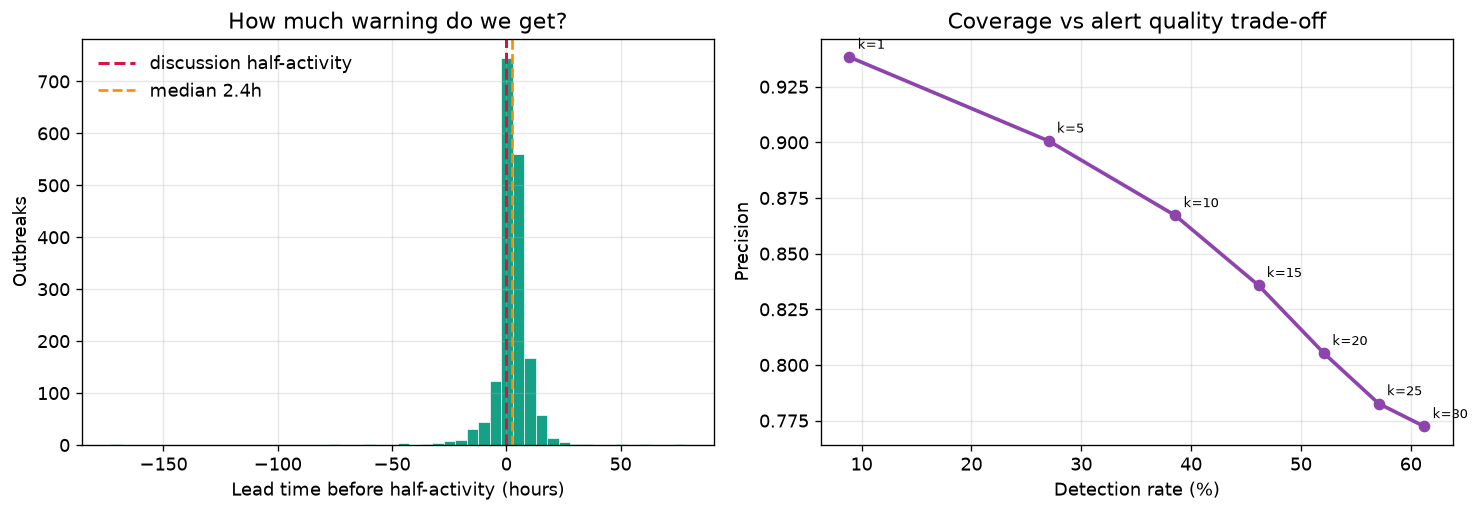

In [8]:
fig,ax=plt.subplots(1,2,figsize=(12.5,4.4))
ax[0].hist(leads,bins=50,color="#16a085",edgecolor="white",linewidth=.4)
ax[0].axvline(0,color="crimson",ls="--",lw=1.8,label="discussion half-activity")
ax[0].axvline(np.median(leads),color="darkorange",ls="--",lw=1.6,label=f"median {np.median(leads):.1f}h")
ax[0].set_xlabel("Lead time before half-activity (hours)"); ax[0].set_ylabel("Outbreaks")
ax[0].set_title("How much warning do we get?"); ax[0].legend(frameon=False); ax[0].grid(alpha=.3)

d=det[det.algorithm=="CELF-detect"].sort_values("k")
ax[1].plot(100*d.detection_rate,d.precision,marker="o",lw=2.2,color="#8e44ad")
for _,r in d.iterrows():
    ax[1].annotate(f"k={int(r.k)}",(100*r.detection_rate,r.precision),
                   textcoords="offset points",xytext=(5,5),fontsize=8)
ax[1].set_xlabel("Detection rate (%)"); ax[1].set_ylabel("Precision")
ax[1].set_title("Coverage vs alert quality trade-off"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("figures/fig_leadtime_precision.png",bbox_inches="tight"); plt.show()

## What to quote

1. **Detection rate at k=20** vs random - your headline impact number
2. **Mean delay** against the median discussion lifespan - the speed claim
3. **Precision** - proves you are not drowning the team in false alarms
4. **Median lead time** - the operational value
5. **CELF-detect vs Top-reach** - shows the optimisation beats the obvious heuristic

Be honest about what is missed: at k=20 roughly half the outbreaks go undetected. Present it as
a cost-benefit curve (more sensors = more coverage, diminishing returns), not as full coverage.